# Train tiếp 5M bước, rồi fine-tune lại với death_penalty = 10

Hai giai đoạn, chạy cho cả `vit` và `lstm`:

1. **Giai đoạn A (extend):** từ `{arm}_dp25_sp0.05_from_pre_s0` train tiếp **5.000.000** bước, giữ nguyên `death_penalty=2.5`, `step_penalty=0.05`. Lưu thành run mới `{arm}_dp25_sp0.05_ext5M_s0`.
2. **Giai đoạn B (death_penalty cao):** lấy kết quả của giai đoạn A làm mô hình ban đầu, fine-tune với `death_penalty=10`. Lưu thành run mới `{arm}_dp10_sp0.05_from_ext5M_s0`.

Run nguồn không bị ghi đè. Run đã có `.pt` + `_log.npy` thì bỏ qua, nên chạy lại sau khi bị ngắt vẫn tiếp tục được (run dở sẽ train lại từ mô hình nguồn của giai đoạn đó).

Ước lượng thời gian: ViT khoảng 315 đến 640 bước/s, LSTM khoảng 1200 bước/s (đo ở các lần trước), nên 5M bước ≈ 2 đến 4 giờ cho ViT và ≈ 70 phút cho LSTM.

In [3]:
from pathlib import Path
import numpy as np
from pacman_rl import PPOConfig, train_ppo, get_device, random_baseline
from pacman_rl.runs import save_run, load_run, list_runs
from pacman_rl.plotting import compare
from pacman_rl.evaluation import ppo_policy, evaluate, watch

device = get_device()
print(device)

cuda


## 1. Tham số

In [2]:
SMOKE = False
SEEDS = [0]
RGB = False                    # phải khớp với model nguồn (False: xám 4 kênh)
RUN_DIR = "runs"

SP = 0.05                      # step_penalty, giữ nguyên ở cả hai giai đoạn
DP_A, DP_B = 2.5, 10.0         # death_penalty: giai đoạn A (giữ như cũ) và giai đoạn B (tăng lên 10)
STEPS_A = 16_384 if SMOKE else 5_000_000
STEPS_B = 16_384 if SMOKE else 1_000_000     # BẠN CHƯA NÓI SỐ BƯỚC CHO GIAI ĐOẠN B: chỉnh ở đây

# lr cho fine-tune/train tiếp (thấp hơn lúc train đầu: ViT 1e-4, LSTM 2.5e-4)
ARMS = {
    "vit":  dict(arch="vit",  lr=5e-5),
    "lstm": dict(arch="lstm", lr=1e-4),
}
# run nguồn của giai đoạn A (kết quả lần fine-tune step_penalty trước)
SRC_A = {"vit": f"vit_dp25_sp{SP}_from_pre_s0", "lstm": f"lstm_dp25_sp{SP}_from_pre_s0"}

def _pre(): return "smoke_" if SMOKE else ""
def _rgb(): return "_rgb" if RGB else ""

def name_a(arm, seed):          # kết quả giai đoạn A
    return f"{_pre()}{arm}_dp25_sp{SP}_ext5M{_rgb()}_s{seed}"

def name_b(arm, seed):          # kết quả giai đoạn B
    return f"{_pre()}{arm}_dp{int(DP_B)}_sp{SP}_from_ext5M{_rgb()}_s{seed}"

def make_cfg(seed, steps, death_penalty, **kw):
    return PPOConfig(
        total_steps=steps, seed=seed, death_penalty=death_penalty, step_penalty=SP, rgb_scale=RGB,
        n_envs=4 if SMOKE else 32,
        n_steps=128 if SMOKE else 512,
        n_minibatches=4,
        save_every=2 if SMOKE else 10,       # đếm theo UPDATE (1 update = 16384 bước): lưu checkpoint mỗi ~164k bước
        log_every=1 if SMOKE else 10,        # in tiến độ mỗi 10 update
        **kw)

def finished(name):
    return Path(f"{RUN_DIR}/{name}.pt").exists() and Path(f"{RUN_DIR}/{name}_log.npy").exists()

def stage(src_of, dst_of, steps, death_penalty, label):
    for seed in SEEDS:
        for arm, kw in ARMS.items():
            src, dst = src_of(arm, seed), dst_of(arm, seed)
            if finished(dst):
                print(f"bỏ qua {dst} (đã có)")
                continue
            assert finished(src), f"run nguồn {src} chưa có hoặc chưa train xong (thiếu .pt / _log.npy)"
            pre = load_run(RUN_DIR, src, "ppo", device).model.train()   # load_run trả eval(); LSTM cuDNN cần train()
            print(f"=== [{label}] {dst} <- {src} | death_penalty {death_penalty}, step_penalty {SP}, {steps:,} bước ===")
            result = train_ppo(cfg=make_cfg(seed, steps, death_penalty, **kw), model=pre,
                               save_path=f"{RUN_DIR}/{dst}.pt", device=device)
            save_run(result, RUN_DIR, dst, append=False)

print([name_a(a, s) for s in SEEDS for a in ARMS])
print([name_b(a, s) for s in SEEDS for a in ARMS])

['vit_dp25_sp0.05_ext5M_s0', 'lstm_dp25_sp0.05_ext5M_s0']
['vit_dp10_sp0.05_from_ext5M_s0', 'lstm_dp10_sp0.05_from_ext5M_s0']


## 2. Giai đoạn A: train tiếp 5M bước (death_penalty 2.5)

In [4]:
stage(lambda arm, seed: SRC_A[arm], name_a, STEPS_A, DP_A, "A")

=== [A] vit_dp25_sp0.05_ext5M_s0 <- vit_dp25_sp0.05_from_pre_s0 | death_penalty 2.5, step_penalty 0.05, 5,000,000 bước ===
PPO: 305 updates x 16384 mẫu = 4,997,120 bước, 32 env song song


c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\torch\nn\functional.py:5504: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)
  attn_output = scaled_dot_product_attention(q, k, v, attn_mask, dropout_p, is_causal)


Update 10/305 | step 163,840 | avg score(20) 711 | 749 lượt | 219 bước/lượt | 0.35 viên NL/lượt | 0.22 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.850 | KL 0.0012 | clipfrac 0.031 | 567 steps/s
Update 20/305 | step 327,680 | avg score(20) 801 | 742 lượt | 221 bước/lượt | 0.36 viên NL/lượt | 0.23 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.832 | KL 0.0007 | clipfrac 0.031 | 562 steps/s
Update 30/305 | step 491,520 | avg score(20) 654 | 756 lượt | 217 bước/lượt | 0.35 viên NL/lượt | 0.21 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.736 | KL 0.0018 | clipfrac 0.067 | 550 steps/s
Update 40/305 | step 655,360 | avg score(20) 741 | 735 lượt | 223 bước/lượt | 0.35 viên NL/lượt | 0.23 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.745 | KL 0.0001 | clipfrac 0.017 | 552 steps/s
Update 50/305 | step 819,200 | avg score(20) 908 | 727 lượt | 225 bước/lượt | 0.37 viên NL/lượt | 0.24 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.861 | KL 0.0009 | clipfrac 0.201 | 545 steps/s
Update 60/305 |

## 3. Giai đoạn B: lấy kết quả giai đoạn A làm mô hình ban đầu, fine-tune với death_penalty = 10

In [5]:
stage(name_a, name_b, STEPS_B, DP_B, "B")

=== [B] vit_dp10_sp0.05_from_ext5M_s0 <- vit_dp25_sp0.05_ext5M_s0 | death_penalty 10.0, step_penalty 0.05, 1,000,000 bước ===
PPO: 61 updates x 16384 mẫu = 999,424 bước, 32 env song song
Update 10/61 | step 163,840 | avg score(20) 750 | 711 lượt | 230 bước/lượt | 0.38 viên NL/lượt | 0.19 ma/lượt | phạt chết 10.0 bước 0.050 | entropy 1.649 | KL 0.0032 | clipfrac 0.132 | 240 steps/s
Update 20/61 | step 327,680 | avg score(20) 750 | 742 lượt | 221 bước/lượt | 0.35 viên NL/lượt | 0.20 ma/lượt | phạt chết 10.0 bước 0.050 | entropy 1.732 | KL 0.0102 | clipfrac 0.244 | 238 steps/s
Update 30/61 | step 491,520 | avg score(20) 870 | 719 lượt | 228 bước/lượt | 0.37 viên NL/lượt | 0.24 ma/lượt | phạt chết 10.0 bước 0.050 | entropy 1.622 | KL 0.0017 | clipfrac 0.036 | 238 steps/s
Update 40/61 | step 655,360 | avg score(20) 772 | 746 lượt | 220 bước/lượt | 0.35 viên NL/lượt | 0.18 ma/lượt | phạt chết 10.0 bước 0.050 | entropy 1.695 | KL 0.0005 | clipfrac 0.055 | 238 steps/s
Update 50/61 | step 819,2

## 4. Đường học: nguồn, giai đoạn A, giai đoạn B

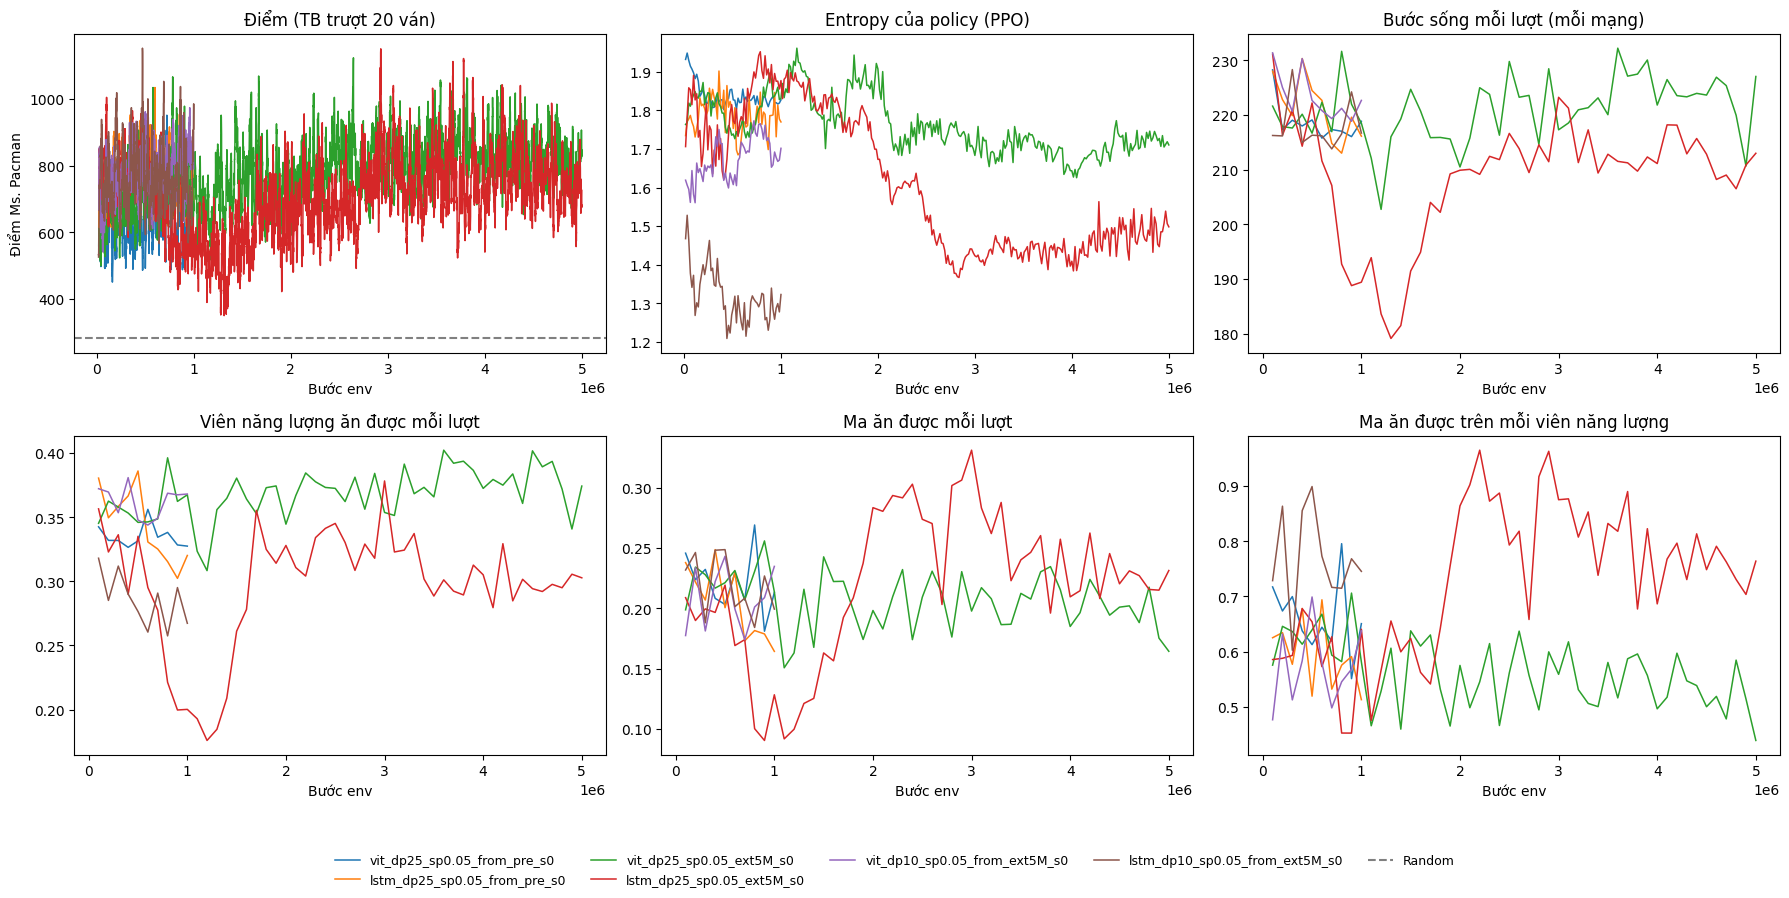

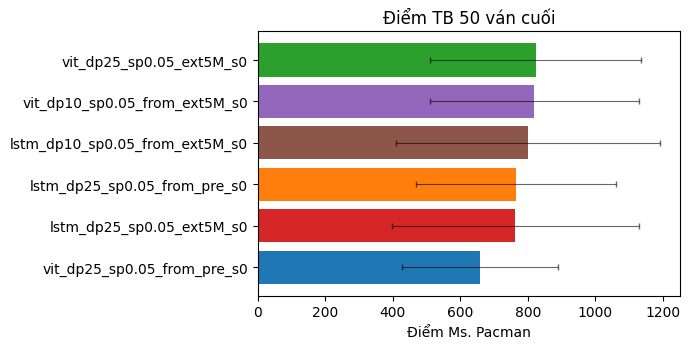

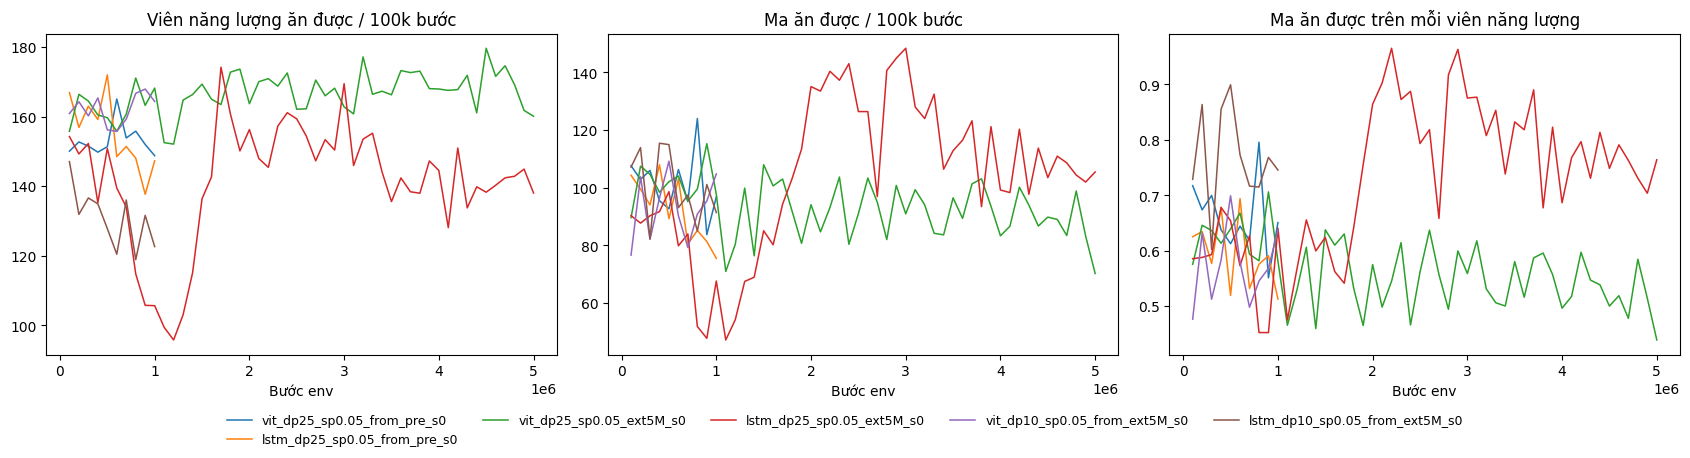

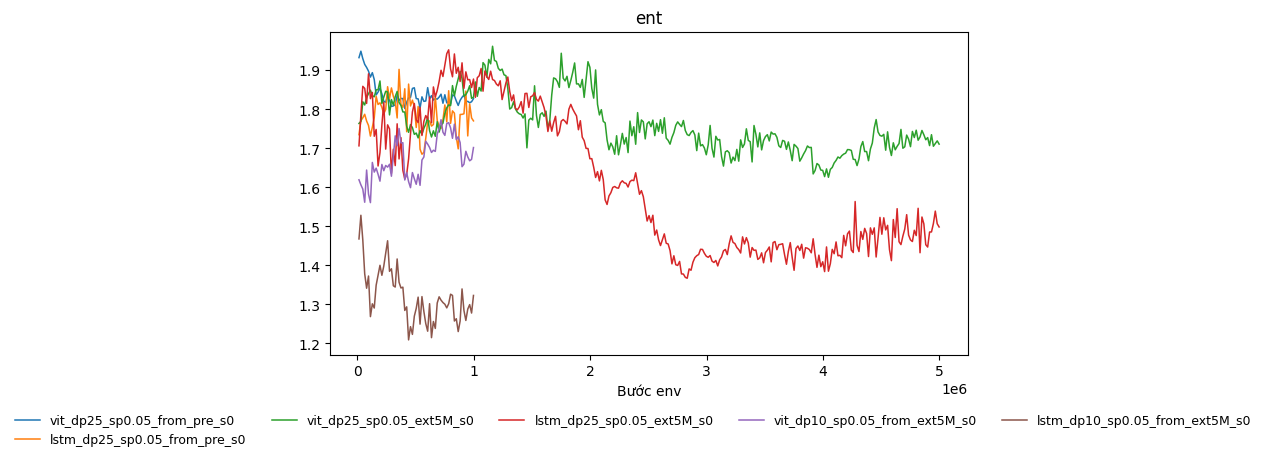

In [6]:
names_a = [name_a(a, s) for s in SEEDS for a in ARMS]
names_b = [name_b(a, s) for s in SEEDS for a in ARMS]
names = list(SRC_A.values()) + names_a + names_b
runs = compare(names=names, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/ext5M_dp10_compare.png")

## 5. Chấm điểm (seed cố định, cùng ván cho mọi model)
Điểm là điểm game thật (không bị ảnh hưởng bởi penalty), nên so sánh được giữa các run.

In [7]:
N_EVAL = 3 if SMOKE else 20
rows = {}
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:44s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")

vit_dp25_sp0.05_from_pre_s0                  TB     660 | std    323 | max   1590
lstm_dp25_sp0.05_from_pre_s0                 TB     680 | std    253 | max   1440
vit_dp25_sp0.05_ext5M_s0                     TB     896 | std    500 | max   2570
lstm_dp25_sp0.05_ext5M_s0                    TB     794 | std    410 | max   2020
vit_dp10_sp0.05_from_ext5M_s0                TB     708 | std    228 | max   1270
lstm_dp10_sp0.05_from_ext5M_s0               TB     710 | std    274 | max   1220


## 6. Xem model chơi (cần màn hình)

In [8]:
WATCH_EPISODES = 1
for n in names_b:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    print(f"=== đang chiếu {n} ===")
    watch(ppo_policy(model, device, greedy=False), episodes=WATCH_EPISODES)

=== đang chiếu vit_dp10_sp0.05_from_ext5M_s0 ===
[play] ván 1: 340 điểm (451 bước)
=== đang chiếu lstm_dp10_sp0.05_from_ext5M_s0 ===
[play] ván 1: 950 điểm (887 bước)


## 7. Giai đoạn C: train tiếp thêm 5M bước
Đổi `C_FROM` ở cell dưới để chọn nguồn. Ở lần chấm điểm trước, run `ext5M` (dp 2.5) đạt TB 896 (ViT) / 794 (LSTM), cao hơn run `dp10` (708 / 710), nên mặc định tiếp từ `ext5M`. Sau cell train có cell vẽ đường học và cell chấm điểm.

In [9]:
# ===== Giai đoạn C: train tiếp thêm 5M bước =====
C_FROM = "A"                   # "A": tiếp từ run ext5M (death_penalty 2.5)  |  "B": tiếp từ run dp10
STEPS_C = 16_384 if SMOKE else 5_000_000
DP_C = DP_A if C_FROM == "A" else DP_B     # giữ đúng death_penalty của run nguồn

src_c = name_a if C_FROM == "A" else name_b

def name_c(arm, seed):
    return f"{_pre()}{arm}_dp{int(DP_C)}_sp{SP}_plus5M_from_{C_FROM}{_rgb()}_s{seed}"

print([name_c(a, s) for s in SEEDS for a in ARMS])
stage(src_c, name_c, STEPS_C, DP_C, "C")

['vit_dp2_sp0.05_plus5M_from_A_s0', 'lstm_dp2_sp0.05_plus5M_from_A_s0']
=== [C] vit_dp2_sp0.05_plus5M_from_A_s0 <- vit_dp25_sp0.05_ext5M_s0 | death_penalty 2.5, step_penalty 0.05, 5,000,000 bước ===
PPO: 305 updates x 16384 mẫu = 4,997,120 bước, 32 env song song
Update 10/305 | step 163,840 | avg score(20) 725 | 740 lượt | 221 bước/lượt | 0.37 viên NL/lượt | 0.21 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.960 | KL 0.0037 | clipfrac 0.101 | 341 steps/s
Update 20/305 | step 327,680 | avg score(20) 648 | 828 lượt | 198 bước/lượt | 0.29 viên NL/lượt | 0.14 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.880 | KL 0.0100 | clipfrac 0.521 | 338 steps/s
Update 30/305 | step 491,520 | avg score(20) 776 | 782 lượt | 210 bước/lượt | 0.32 viên NL/lượt | 0.18 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.873 | KL 0.0018 | clipfrac 0.078 | 339 steps/s
Update 40/305 | step 655,360 | avg score(20) 968 | 727 lượt | 225 bước/lượt | 0.41 viên NL/lượt | 0.23 ma/lượt | phạt chết 2.5 bước 0.050 | entrop

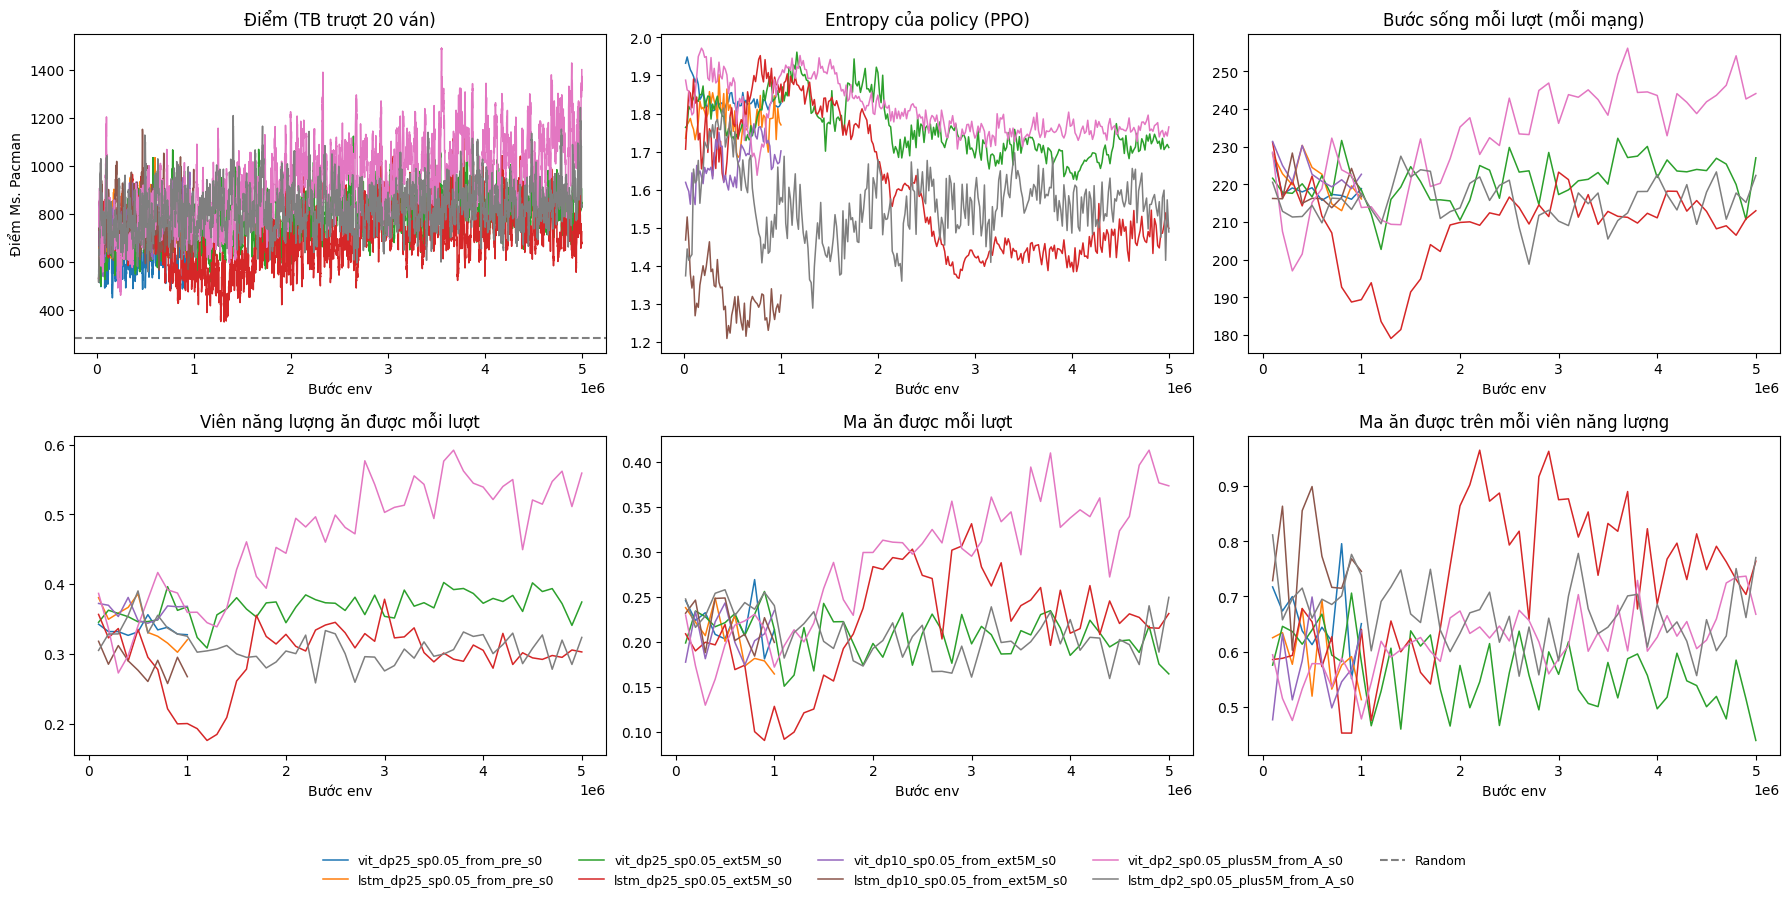

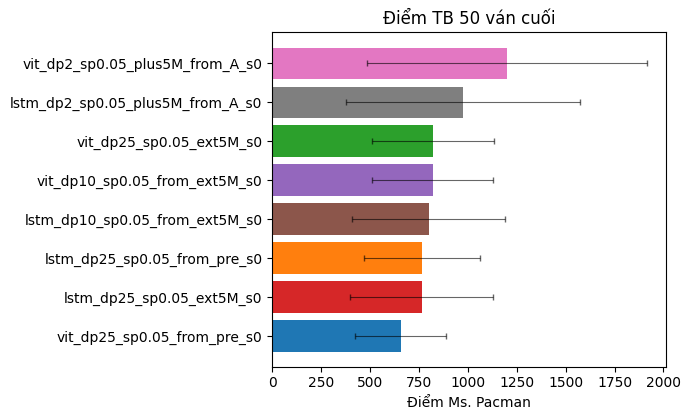

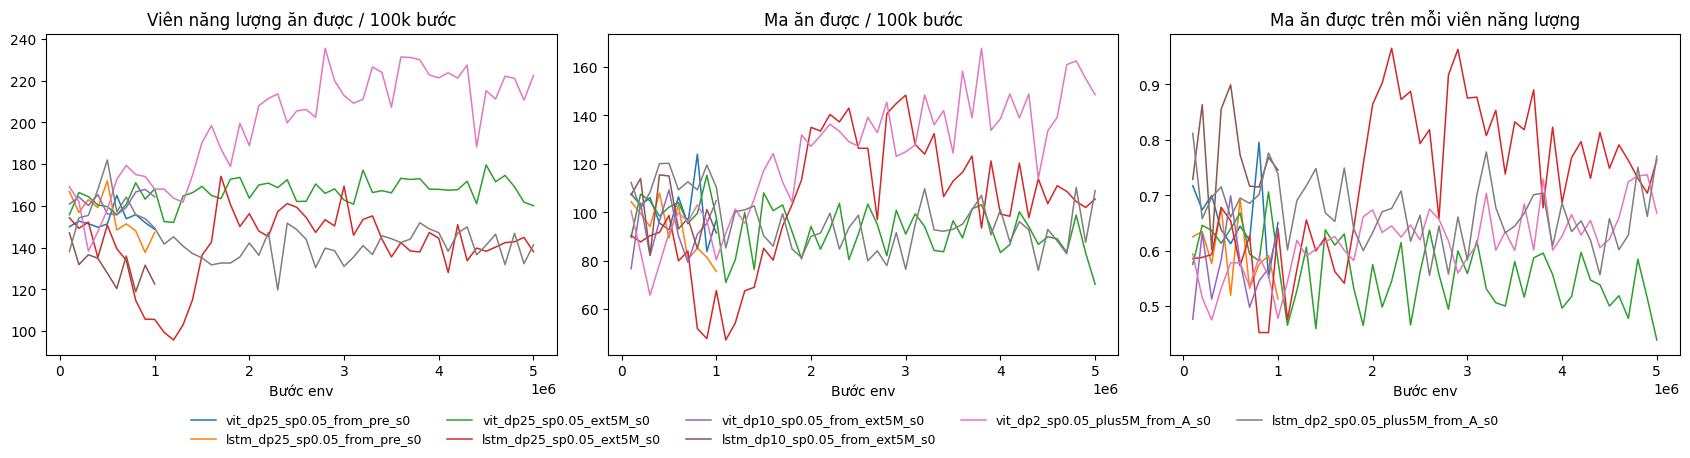

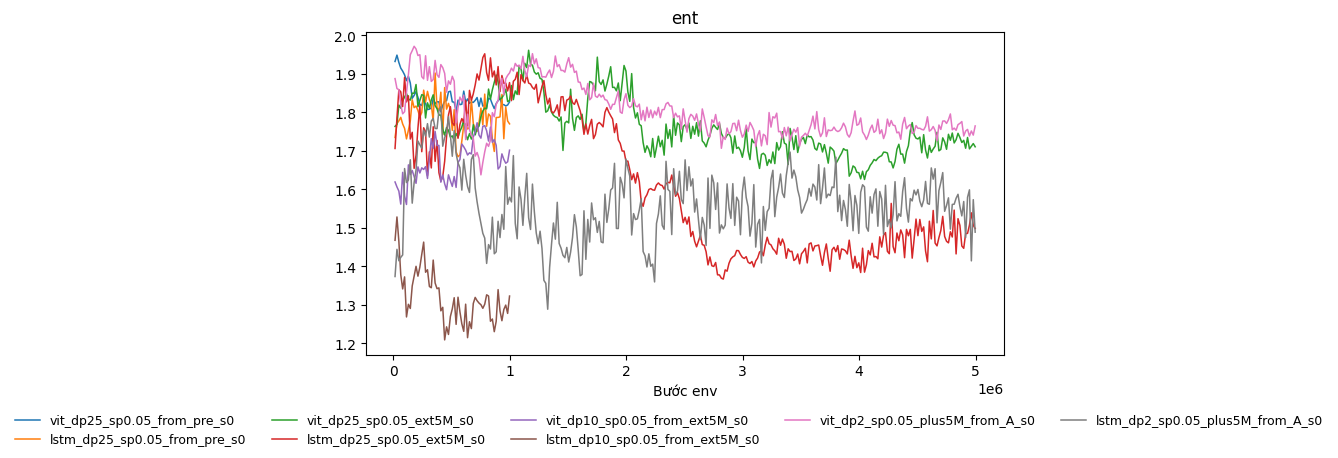

In [10]:
names_c = [name_c(a, s) for s in SEEDS for a in ARMS]
names_all = list(SRC_A.values()) + names_a + names_b + names_c
runs = compare(names=names_all, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/ext5M_dp10_plus5M_compare.png")

In [11]:
# chấm điểm lại cả 3 giai đoạn, cùng seed 1000 (điểm game thật, so sánh được giữa các run)
rows = {}
for n in names_all:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:44s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")

vit_dp25_sp0.05_from_pre_s0                  TB     499 | std    163 | max    900
lstm_dp25_sp0.05_from_pre_s0                 TB     752 | std    284 | max   1570
vit_dp25_sp0.05_ext5M_s0                     TB     835 | std    294 | max   1400
lstm_dp25_sp0.05_ext5M_s0                    TB     849 | std    458 | max   1940
vit_dp10_sp0.05_from_ext5M_s0                TB     744 | std    237 | max   1290
lstm_dp10_sp0.05_from_ext5M_s0               TB     748 | std    309 | max   1550
vit_dp2_sp0.05_plus5M_from_A_s0              TB     986 | std    823 | max   4290
lstm_dp2_sp0.05_plus5M_from_A_s0             TB     862 | std    384 | max   2060


In [8]:
from pacman_rl import watch_probs
model = load_run(RUN_DIR, "vit_dp2_sp0.05_plus5M_from_A_s0", "ppo", device).model.to(device).eval()
watch_probs(model, device, greedy=True, eps=0.03)    # phím q để thoát

[watch_probs] 1000 điểm (720 bước)


1000.0

In [ ]:
WATCH_EPISODES = 1
for n in ["lstm_dp2_sp0.05_plus5M_from_A_s0"]:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    print(f"=== đang chiếu {n} ===")
    watch(ppo_policy(model, device, greedy=True), episodes=WATCH_EPISODES)

In [ ]:
# ===== Giai đoạn D (chỉ LSTM): train tiếp thêm 5M bước từ run giai đoạn C =====
# Cell tự đủ: chạy được ngay sau khi restart kernel, không cần chạy các cell phía trên.
from pathlib import Path
from pacman_rl import PPOConfig, train_ppo, get_device
from pacman_rl.runs import save_run, load_run

device = get_device()

# ---- tham số ----
SMOKE = False                  # True: chạy thử vài update
SEED = 0
RGB = False                    # phải khớp với model nguồn (False: xám 4 kênh)
RUN_DIR = "runs"
SP = 0.05                      # step_penalty (giữ như giai đoạn C)
DP = 2.5                       # death_penalty (giữ như giai đoạn C)
LR_D = 1e-4                    # lr như giai đoạn C; đổi để thử lr khác (vd 2.5e-4)
STEPS_D = 16_384 if SMOKE else 5_000_000

SRC = "lstm_dp2_sp0.05_plus5M_from_A_s0"                               # run giai đoạn C (tên cũ bị cắt thành dp2)
DST = ("smoke_" if SMOKE else "") + f"lstm_dp{DP:g}_sp{SP}_plus10M_from_C" + ("_rgb" if RGB else "") + f"_s{SEED}"

def finished(name):
    return Path(f"{RUN_DIR}/{name}.pt").exists() and Path(f"{RUN_DIR}/{name}_log.npy").exists()

cfg = PPOConfig(
    arch="lstm", lr=LR_D, total_steps=STEPS_D, seed=SEED,
    death_penalty=DP, step_penalty=SP, rgb_scale=RGB,
    n_envs=4 if SMOKE else 32,
    n_steps=128 if SMOKE else 512,
    n_minibatches=4,
    save_every=2 if SMOKE else 10,       # đếm theo UPDATE (1 update = 16384 bước)
    log_every=1 if SMOKE else 10,
)

# ---- train ----
if finished(DST):
    print(f"bỏ qua {DST} (đã có)")
else:
    assert finished(SRC), f"run nguồn {SRC} chưa có hoặc chưa train xong (thiếu .pt / _log.npy trong {RUN_DIR}/)"
    pre = load_run(RUN_DIR, SRC, "ppo", device).model.train()          # load_run trả eval(); LSTM cuDNN cần train()
    print(f"=== [D] {DST} <- {SRC} | lr {LR_D}, death_penalty {DP}, step_penalty {SP}, {STEPS_D:,} bước ===")
    result = train_ppo(cfg=cfg, model=pre, save_path=f"{RUN_DIR}/{DST}.pt", device=device)
    save_run(result, RUN_DIR, DST, append=False)

=== [D] lstm_dp2.5_sp0.05_plus10M_from_C_s0 <- lstm_dp2_sp0.05_plus5M_from_A_s0 | lr 0.0001, death_penalty 2.5, step_penalty 0.05, 5,000,000 bước ===
PPO: 305 updates x 16384 mẫu = 4,997,120 bước, 32 env song song
Update 10/305 | step 163,840 | avg score(20) 947 | 745 lượt | 220 bước/lượt | 0.25 viên NL/lượt | 0.19 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.344 | KL 0.0157 | clipfrac 0.326 | 600 steps/s
Update 20/305 | step 327,680 | avg score(20) 918 | 743 lượt | 221 bước/lượt | 0.31 viên NL/lượt | 0.24 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.390 | KL 0.0058 | clipfrac 0.153 | 700 steps/s
Update 30/305 | step 491,520 | avg score(20) 704 | 761 lượt | 215 bước/lượt | 0.29 viên NL/lượt | 0.21 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.368 | KL 0.0054 | clipfrac 0.156 | 632 steps/s
Update 40/305 | step 655,360 | avg score(20) 802 | 744 lượt | 220 bước/lượt | 0.30 viên NL/lượt | 0.20 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.387 | KL 0.0090 | clipfrac 0.192 | 591 steps/

In [ ]:
names_d = ["lstm_dp2.5_sp0.05_plus10M_from_C_s0"]
names_plot = [name_a("lstm", 0), name_c("lstm", 0)] + names_d
runs = compare(names=names_plot, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/lstm_A_C_D_compare.png")


NameError: name 'name_a' is not defined

In [6]:
from pacman_rl import watch_probs
RUN_DIR = "runs"

model = load_run(RUN_DIR, "lstm_dp2.5_sp0.05_plus10M_from_C_s0", "ppo", device).model.to(device).eval()
watch_probs(model, device, greedy=True, eps=0.03)    # phím q để thoát

[watch_probs] 960 điểm (659 bước)


960.0